# Py09: Regression 1: Simple Linear Regression


In [19]:
# Load your data and libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = 'ames_lite.csv'
df_raw = pd.read_csv(path)

number_columns = df_raw.select_dtypes(include=['number']).columns.tolist()
categorical_columns = df_raw.select_dtypes(include=['object', 'category']).columns.tolist()

print("DataFrame dtypes:")
print(df_raw.dtypes)
df_raw.describe()

df_raw

DataFrame dtypes:
building_type           str
central_ac_yn           str
sq_ft_first_floor     int64
sq_ft_second_floor    int64
bathrooms             int64
bedrooms              int64
year_sold             int64
sale_price            int64
dtype: object


/var/folders/w6/p7gv5g6166vbk07p2pwdxjqr0000gp/T/ipykernel_18221/3859598983.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_raw.select_dtypes(include=['object', 'category']).columns.tolist()


,building_type,central_ac_yn,sq_ft_first_floor,sq_ft_second_floor,bathrooms,bedrooms,year_sold,sale_price
0,OneFam,Y,916,910,1,4,2009,155000
1,OneFam,Y,1291,0,1,2,2008,173000
2,Duplex,N,1088,1040,2,4,2009,62500
3,OneFam,Y,662,662,1,3,2010,122000
4,OneFam,Y,967,0,1,2,2007,99900
...,...,...,...,...,...,...,...,...
2529,OneFam,Y,4692,950,2,3,2008,160000
2530,OneFam,Y,1533,0,2,2,2006,280000
2531,OneFam,Y,1824,0,2,2,2007,302000
2532,OneFam,Y,1444,700,2,4,2007,277000


# Step 1: Data Quality

Examine these fields for data issues. Describe each of these fields. 

- building_type: 
- central_ac_yn: 
- sq_ft_first_floor: 
- sq_ft_second_floor: 
- bathrooms: 
- bedrooms: 
- year_sold: 
- sale_price: 

Data Cleanup Steps:

- Create a new df to work with
- Convert any text columns that can be easily categorized to 1/0
- Combine related columns
- Remove rows with extreme values (e.g., above 99th percentile)


In [20]:
# Data Cleanup

# Create a new df to work with 
df = df_raw.copy()

# Feature creation:

# Create a total sq foot
df['sq_floor'] = df['sq_ft_first_floor'] + df['sq_ft_second_floor']

# has a 2nd floor
df['has_2nd_floor'] = df['sq_ft_second_floor'] > 0

# has_ac column
df['has_ac'] = df['central_ac_yn'] == 'Y'

# create a is_duplex column
df['is_duplex'] = df['building_type'] == 'Duplex'

# Remove old columns
df = df.drop(columns=['sq_ft_first_floor', 'sq_ft_second_floor', 'building_type'])

# Step 2: Remove outliers
old_record_count = df.shape[0]



# Remove rows with extreme sale prices (e.g., above 99th percentile)
# upper_limit = df['?'].quantile(0.99)
# df = df[? <= upper_limit]

print(f"Removed {old_record_count - df.shape[0]} outlier records")

Removed 0 outlier records


# Step 2: Visualize data

Use a pairplot and histograms to visualize the data.

/var/folders/w6/p7gv5g6166vbk07p2pwdxjqr0000gp/T/ipykernel_18221/3758709882.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()


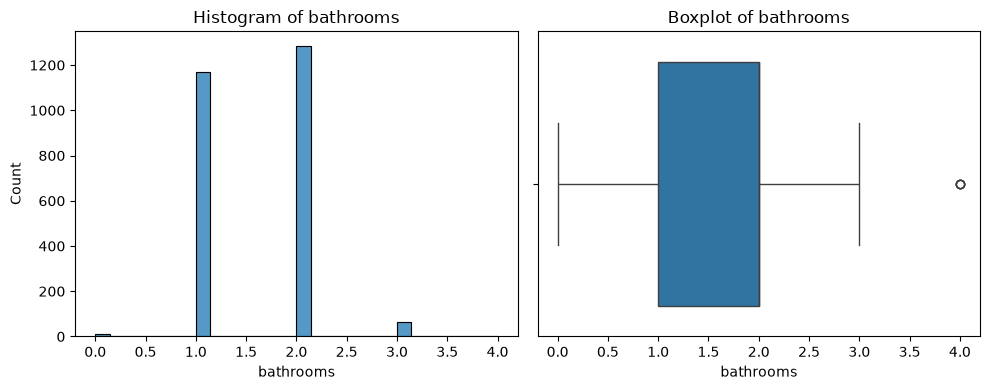

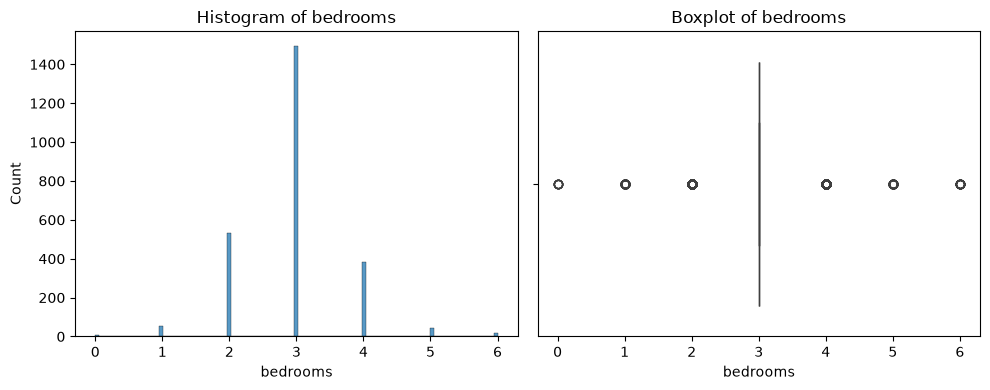

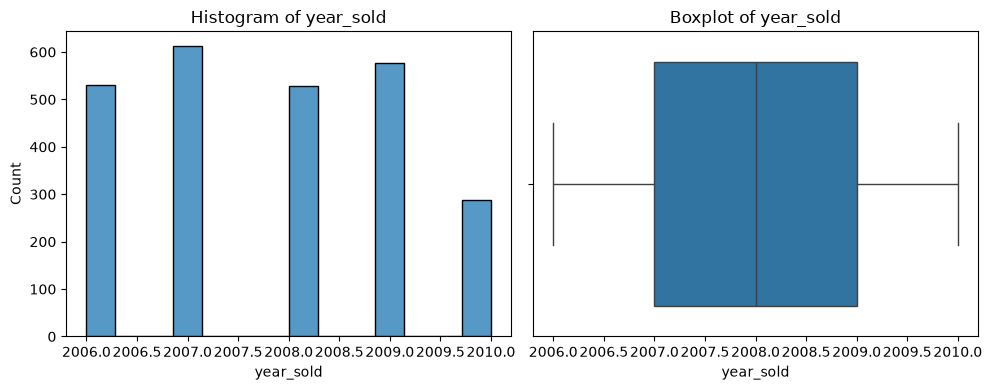

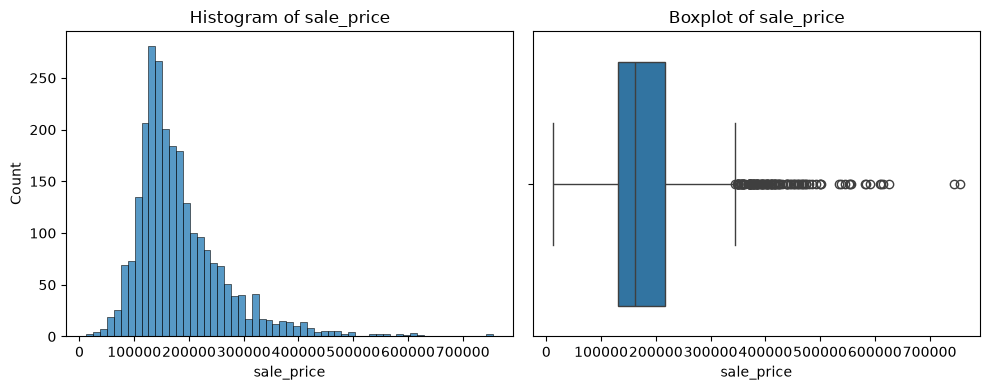

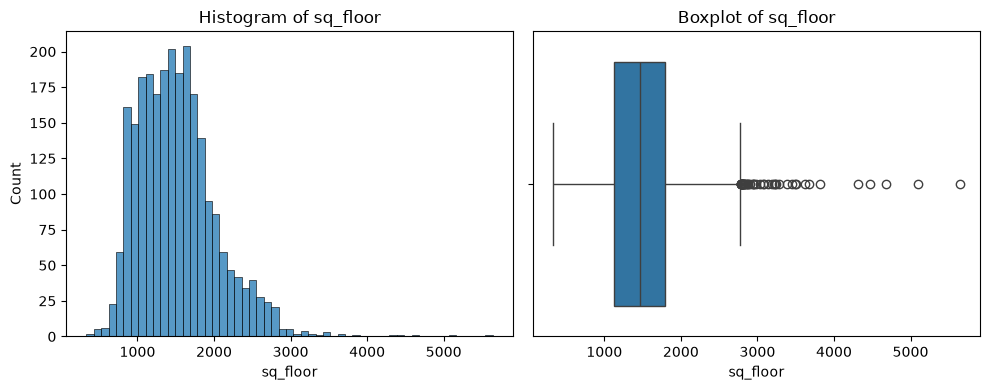

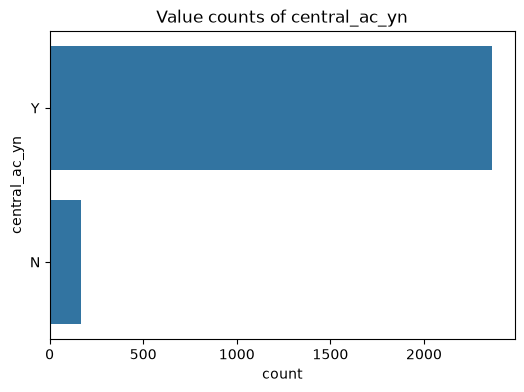

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

number_columns = df.select_dtypes(include=['number']).columns.tolist()
text_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Print a histogram and boxplot for each numeric column
for col in number_columns:
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    sns.histplot(df[col])
    plt.title(f'Histogram of {col}')
    
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col].dropna())
    plt.title(f'Boxplot of {col}')
    
    plt.tight_layout()
    plt.show()

# Print a chart showing the distribution of values for each text column
for col in text_columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(y=df[col], order=df[col].value_counts().index)
    plt.title(f'Value counts of {col}')
    plt.show()

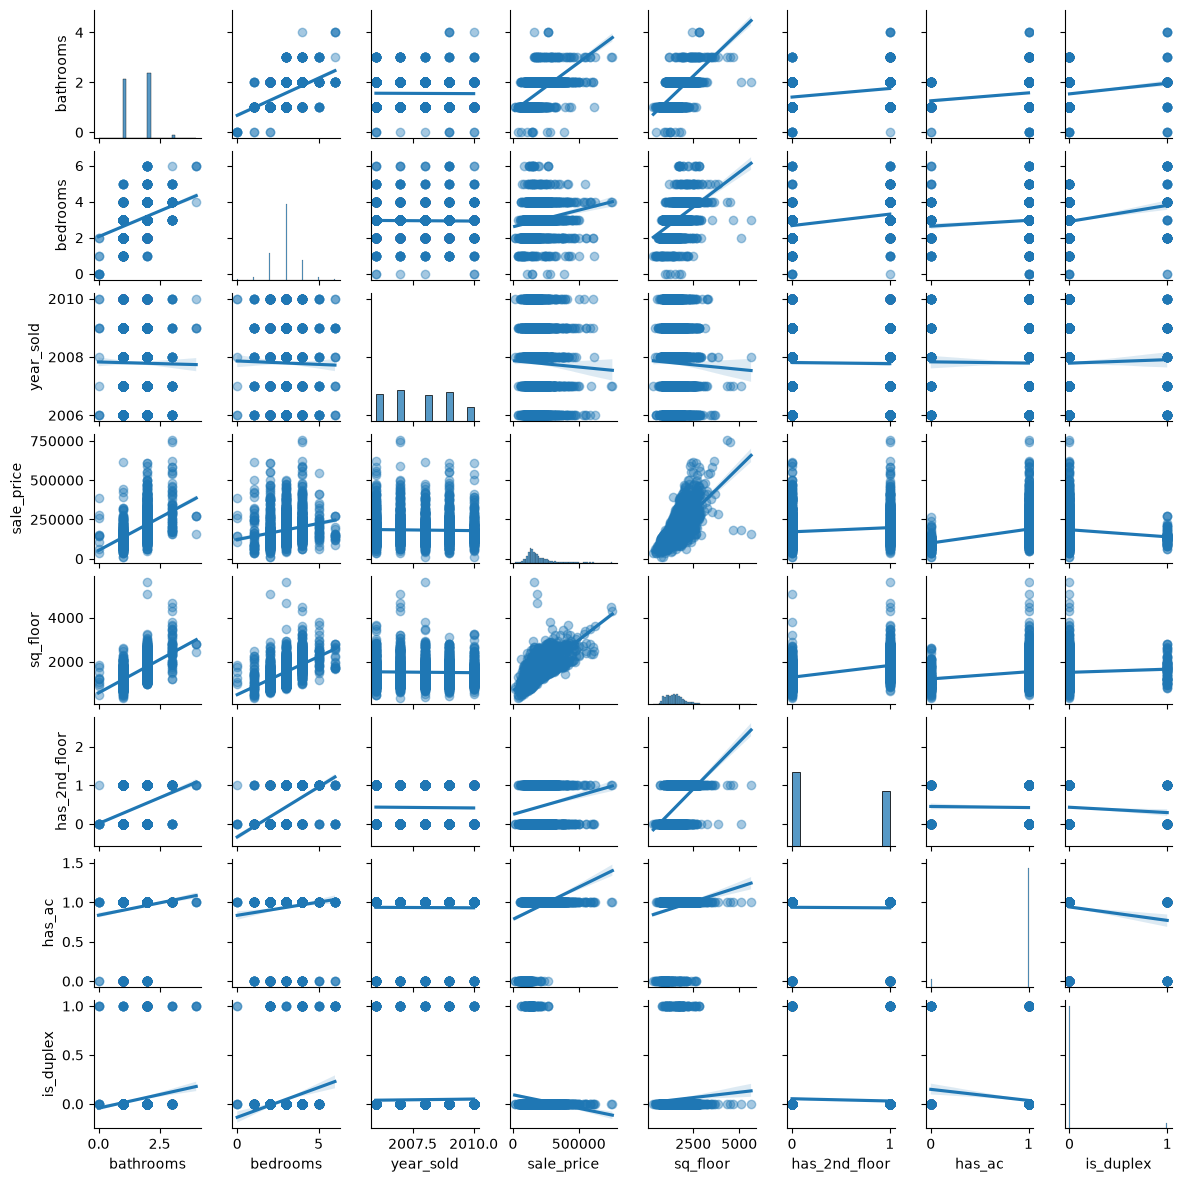

In [22]:
# Plot a pairs printout of each of the numeric variables
# Note that we use the alpha to set the visibility of the points to avoid overplotting. This also works well for large datasets.

sns.pairplot(df, kind='reg', height=1.5, plot_kws={'scatter_kws': {'alpha': 0.4}})
plt.show()

# Step 3: Build a simple linear regression model

Key items:

- Residuals = errors in each row between actual & predicted
- Standard Error = the squared difference between the predicted and actual values. 
- Coefficients:
  - Estimate: value of the change in input to output
  - Standard Error: averages squared diff between prediction / actual
  - p Value: probability of the estimate being a result of random chance
- Residual standard error: the overall avg difference between actual
    and predicted for the entire model.
  - Adj R^2,  the % of variation explained by the model

In [23]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Get variables for prediction
X = df[['sq_floor', 'bathrooms', 'is_duplex']]
y = df['sale_price']

# Fit the model
X = sm.add_constant(X)  # Adds a constant term to the predictor
model = sm.OLS(y, X).fit()
predictions = model.predict(X)
print(model.summary())



                            OLS Regression Results                            
Dep. Variable:             sale_price   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.579
Method:                 Least Squares   F-statistic:                     1161.
Date:                Fri, 02 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:16:56   Log-Likelihood:                -31168.
No. Observations:                2534   AIC:                         6.234e+04
Df Residuals:                    2530   BIC:                         6.237e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5559.0657   3485.592     -1.595      0.1

RMSE: 53146.82358101096
R²: 0.579145655758314


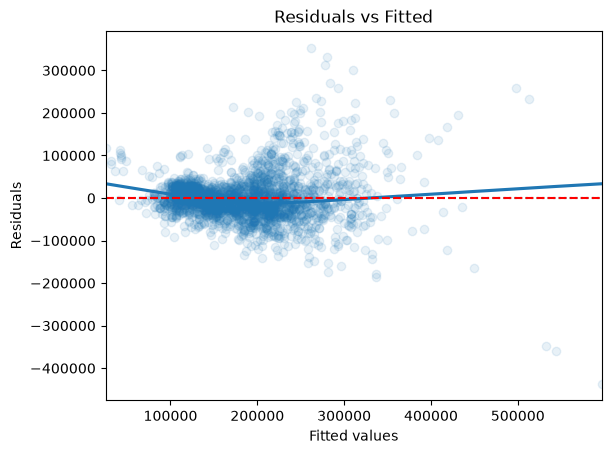

In [24]:
resid = model.resid
fitted = model.fittedvalues
rmse_value = np.sqrt(np.mean(resid**2))
print(f"RMSE: {rmse_value}")
r2_value = model.rsquared
print(f"R²: {r2_value}")

# Plot resduals
sns.residplot(x=fitted, y=resid, lowess=True, scatter_kws={'alpha': 0.1})
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')
plt.axhline(0, color='red', linestyle='--')
plt.show()